# Generalized Procrustes Analysis Workflow for M2 Coordinate Data

This notebook performs the Procrustes alignment step for mandibular second molar coordinate data.

It is written as a repository-ready version  so that readers can download `Example_Data.csv` and run the workflow themselves.

## What this notebook does

1. Loads `Example_Data.csv`.
2. Detects coordinate columns named `X1`, `Y1`, `X2`, `Y2`, ..., `X23`, `Y23`.
3. Reshapes the flat coordinate table into specimen-by-landmark coordinate arrays.
4. Treats landmarks 1 and 23 as fixed anatomical landmarks.
5. Treats landmarks 2 through 22 as semilandmarks.
6. Performs iterative Generalized Procrustes Analysis.
7. Optionally slides semilandmarks along local outline tangents using a Procrustes-distance criterion.
8. Saves Procrustes-aligned coordinates and quality-control outputs.

## Important landmark clarification

The coordinate file contains 23 landmark points. Therefore, the final fixed landmark is `X23, Y23`, not `X24, Y24`.

## Software note

This notebook implements the Procrustes/GPA workflow in Python. It does not require R or the `geomorph` package to run.


## 1. Edit file paths and analysis settings



In [ ]:
# -----------------------------
# Editable settings
# -----------------------------

from pathlib import Path

#INPUT_FILE = Path("../../data/Example_Data.csv") # <- Change Input Paths as needed
INPUT_FILE = Path("INSERT FILE PATH HERE")
# Folder where Procrustes/GPA outputs will be saved.
OUTPUT_DIR = Path("../../results/gpa") # <- Change Output Paths as needed

# Fixed anatomical landmarks.
# These are 1-based landmark numbers corresponding to:
# 1  = X1, Y1
# 23 = X23, Y23
FIXED_LANDMARKS = [1,13,23]

# Semilandmarks along the entoconid outline.
# These are 1-based landmark numbers corresponding to:
# X2/Y2 through X22/Y22.
SEMILANDMARKS = list(range(2, 12)) + list(range(14, 22))

# Set this to True to slide semilandmarks along local outline tangents during GPA.
# This implements a Procrustes-distance sliding approximation in Python.
SLIDE_SEMILANDMARKS = False

# GPA convergence settings.
MAX_ITERATIONS = 100
TOLERANCE = 1e-7

# Save plots as PNG files.
SAVE_PLOTS = True

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Input file: {INPUT_FILE}")
print(f"Output folder: {OUTPUT_DIR}")
print(f"Fixed landmarks: {FIXED_LANDMARKS}")
print(f"Semilandmarks: {SEMILANDMARKS[0]} through {SEMILANDMARKS[-1]}")
print(f"Slide semilandmarks: {SLIDE_SEMILANDMARKS}")


Input file:/Example_Data_with_CS_calibrated.csv
Output folder: ../../results/gpa
Fixed landmarks: [1, 13, 23]
Semilandmarks: 2 through 21
Slide semilandmarks: False


## 2. Import packages and define helper functions

In [99]:
# -----------------------------
# Imports and helper functions
# -----------------------------

from __future__ import annotations

import re
from typing import Iterable, List, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from scipy.linalg import orthogonal_procrustes


def clean_column_names(df: pd.DataFrame) -> pd.DataFrame:
    """
    Clean column names by removing whitespace and invisible spacing characters.

    This makes the notebook more tolerant of CSV files exported from spreadsheets.
    """
    df = df.copy()
    df.columns = (
        df.columns.astype(str)
        .str.replace(r"\s+", "", regex=True)
        .str.replace("\ufeff", "", regex=False)
    )
    return df


def coordinate_sort_key(column_name: str) -> tuple[int, int]:
    """
    Sort coordinate columns in anatomical order:
    X1, Y1, X2, Y2, ..., X23, Y23.
    """
    match = re.fullmatch(r"([XY])(\d+)", column_name)
    if match is None:
        return (10_000, 10_000)

    axis, number = match.groups()
    axis_order = 0 if axis == "X" else 1
    return (int(number), axis_order)


def find_coordinate_columns(df: pd.DataFrame) -> List[str]:
    """
    Detect coordinate columns named X1, Y1, X2, Y2, etc.
    """
    coordinate_columns = [
        col for col in df.columns
        if re.fullmatch(r"[XY]\d+", str(col))
    ]
    coordinate_columns = sorted(coordinate_columns, key=coordinate_sort_key)

    if len(coordinate_columns) == 0:
        raise ValueError(
            "No coordinate columns were found. Expected columns named like "
            "X1, Y1, X2, Y2, ..., X23, Y23."
        )

    if len(coordinate_columns) % 2 != 0:
        raise ValueError(
            f"Found {len(coordinate_columns)} coordinate columns, which is not even. "
            "Each landmark should have both an X and a Y coordinate."
        )

    landmark_numbers = sorted(
        {int(re.fullmatch(r"[XY](\d+)", col).group(1)) for col in coordinate_columns}
    )

    missing_pairs = []
    for n in landmark_numbers:
        if f"X{n}" not in coordinate_columns or f"Y{n}" not in coordinate_columns:
            missing_pairs.append(n)

    if missing_pairs:
        raise ValueError(
            "Some landmarks are missing either X or Y coordinates: "
            + ", ".join(map(str, missing_pairs))
        )

    return coordinate_columns


def ensure_numeric_coordinates(df: pd.DataFrame, coordinate_columns: Iterable[str]) -> pd.DataFrame:
    """
    Convert coordinate columns to numeric values and fail clearly if conversion fails.
    """
    coords = df[list(coordinate_columns)].copy()

    for col in coords.columns:
        coords[col] = pd.to_numeric(coords[col], errors="coerce")

    missing_counts = coords.isna().sum()
    problematic = missing_counts[missing_counts > 0]

    if not problematic.empty:
        raise ValueError(
            "Some coordinate columns contain missing or non-numeric values after conversion:\n"
            + problematic.to_string()
            + "\nPlease check the input CSV."
        )

    return coords


def reshape_coordinates(coords_df: pd.DataFrame) -> np.ndarray:
    """
    Reshape flat coordinate columns into a 3D array:
    specimens x landmarks x dimensions.
    """
    n_specimens = coords_df.shape[0]
    n_landmarks = coords_df.shape[1] // 2
    return coords_df.to_numpy(dtype=float).reshape(n_specimens, n_landmarks, 2)


def centroid_size(shape: np.ndarray) -> float:
    """
    Calculate centroid size for a single landmark configuration.
    """
    centered = shape - shape.mean(axis=0)
    return float(np.sqrt(np.sum(centered ** 2)))


def center_and_scale(shape: np.ndarray) -> np.ndarray:
    """
    Center a shape at the origin and scale it to unit centroid size.
    """
    centered = shape - shape.mean(axis=0)
    size = np.sqrt(np.sum(centered ** 2))

    if size == 0:
        raise ValueError("A specimen has centroid size 0 and cannot be scaled.")

    return centered / size


def normalize_mean_shape(shape: np.ndarray) -> np.ndarray:
    """
    Center and scale the mean shape to unit centroid size.
    """
    return center_and_scale(shape)


def align_shape_to_reference(shape: np.ndarray, reference: np.ndarray) -> np.ndarray:
    """
    Rotate a centered/scaled shape to best match the reference shape.

    Both input shapes should already be centered and scaled.
    """
    rotation_matrix, _ = orthogonal_procrustes(shape, reference)
    return shape @ rotation_matrix


def procrustes_distance(shape: np.ndarray, reference: np.ndarray) -> float:
    """
    Calculate Procrustes distance between an aligned shape and reference.
    """
    return float(np.sqrt(np.sum((shape - reference) ** 2)))


def landmark_numbers_to_indices(landmark_numbers: Iterable[int], n_landmarks: int) -> List[int]:
    """
    Convert 1-based landmark numbers to 0-based Python indices.
    """
    indices = [n - 1 for n in landmark_numbers]

    invalid = [n for n in landmark_numbers if n < 1 or n > n_landmarks]
    if invalid:
        raise ValueError(
            f"Invalid landmark numbers {invalid}. "
            f"Valid landmark numbers are 1 through {n_landmarks}."
        )

    return indices


## 3. Define GPA and semilandmark sliding functions

In [102]:
# -----------------------------
# GPA and semilandmark sliding functions
# -----------------------------

def slide_semilandmarks_to_reference(
    shape: np.ndarray,
    reference: np.ndarray,
    semilandmark_indices: Iterable[int],
) -> np.ndarray:
    """
    Slide semilandmarks along local outline tangents toward the reference shape.

    This is a Python implementation of semilandmark sliding using a
    Procrustes-distance criterion. For each semilandmark, the function estimates
    the local tangent from the neighboring points and moves the semilandmark
    along that tangent to minimize squared distance to the current reference.

    Fixed landmarks are not moved by this function.

    Parameters
    ----------
    shape:
        Aligned specimen shape, landmarks x 2.
    reference:
        Current GPA mean/reference shape, landmarks x 2.
    semilandmark_indices:
        0-based indices of semilandmarks to slide.

    Returns
    -------
    slid_shape:
        Shape after semilandmark sliding.
    """
    slid_shape = shape.copy()
    n_landmarks = shape.shape[0]

    for idx in semilandmark_indices:
        if idx <= 0 or idx >= n_landmarks - 1:
            # This workflow expects semilandmarks to be internal points along
            # the outline. Endpoint semilandmarks are skipped for safety.
            continue

        previous_point = slid_shape[idx - 1]
        next_point = slid_shape[idx + 1]

        tangent = next_point - previous_point
        tangent_norm = np.linalg.norm(tangent)

        if tangent_norm == 0:
            continue

        tangent = tangent / tangent_norm

        current_point = slid_shape[idx]
        target_point = reference[idx]

        # Project the current-to-target vector onto the local tangent.
        displacement = np.dot(target_point - current_point, tangent) * tangent

        slid_shape[idx] = current_point + displacement

    return slid_shape


def generalized_procrustes_analysis(
    shapes: np.ndarray,
    semilandmark_indices: Iterable[int] | None = None,
    slide_semilandmarks: bool = True,
    max_iterations: int = 100,
    tolerance: float = 1e-7,
) -> Tuple[np.ndarray, np.ndarray, pd.DataFrame]:
    """
    Perform iterative Generalized Procrustes Analysis.

    The workflow:
    1. Centers and scales each specimen to unit centroid size.
    2. Iteratively rotates each specimen to the current mean shape.
    3. Optionally slides semilandmarks along local tangents to improve
       correspondence relative to the current mean shape.
    4. Recalculates the mean shape until convergence.

    Returns
    -------
    aligned_shapes:
        Procrustes-aligned shapes, specimens x landmarks x 2.
    mean_shape:
        Final GPA mean shape.
    history:
        DataFrame summarizing GPA convergence by iteration.
    """
    if shapes.ndim != 3 or shapes.shape[2] != 2:
        raise ValueError(
            "Input shapes must have shape: specimens x landmarks x 2."
        )

    if semilandmark_indices is None:
        semilandmark_indices = []

    # Initial centering/scaling.
    preshapes = np.array([center_and_scale(shape) for shape in shapes])

    # Initial reference is the normalized average of preshapes.
    reference = normalize_mean_shape(np.mean(preshapes, axis=0))

    history_records = []

    for iteration in range(1, max_iterations + 1):
        aligned = np.zeros_like(preshapes)

        for i, shape in enumerate(preshapes):
            aligned_shape = align_shape_to_reference(shape, reference)

            if slide_semilandmarks and len(list(semilandmark_indices)) > 0:
                aligned_shape = slide_semilandmarks_to_reference(
                    aligned_shape,
                    reference,
                    semilandmark_indices,
                )
                # Re-center/scale after sliding, then rotate again to reference.
                aligned_shape = center_and_scale(aligned_shape)
                aligned_shape = align_shape_to_reference(aligned_shape, reference)

            aligned[i] = aligned_shape

        new_reference = normalize_mean_shape(np.mean(aligned, axis=0))
        mean_shift = float(np.sqrt(np.sum((new_reference - reference) ** 2)))
        mean_distance = float(
            np.mean([procrustes_distance(shape, new_reference) for shape in aligned])
        )

        history_records.append(
            {
                "iteration": iteration,
                "mean_shape_shift": mean_shift,
                "mean_procrustes_distance_to_mean": mean_distance,
            }
        )

        reference = new_reference
        preshapes = aligned

        if mean_shift < tolerance:
            break

    history = pd.DataFrame(history_records)
    return aligned, reference, history


def flatten_shapes(aligned_shapes: np.ndarray, coordinate_columns: List[str]) -> pd.DataFrame:
    """
    Convert aligned shape array back to a flat coordinate table.
    """
    n_specimens = aligned_shapes.shape[0]
    flat = aligned_shapes.reshape(n_specimens, aligned_shapes.shape[1] * 2)
    return pd.DataFrame(flat, columns=coordinate_columns)


## 4. Load and validate the input data

In [105]:
# -----------------------------
# Load and validate the input data
# -----------------------------

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"Input file not found: {INPUT_FILE}\n\n"
        "Check the path in the editable settings cell. "
        "If you are running this notebook from a different folder, update INPUT_FILE."
    )

data = pd.read_csv(INPUT_FILE)
data = clean_column_names(data)

print(f"Loaded {data.shape[0]} specimens and {data.shape[1]} columns.")

coordinate_columns = find_coordinate_columns(data)
coords_df = ensure_numeric_coordinates(data, coordinate_columns)

n_landmarks = len(coordinate_columns) // 2
fixed_indices = landmark_numbers_to_indices(FIXED_LANDMARKS, n_landmarks)
semilandmark_indices = landmark_numbers_to_indices(SEMILANDMARKS, n_landmarks)

# Metadata are all columns that are not detected coordinate columns.
metadata_columns = [col for col in data.columns if col not in coordinate_columns]
metadata_df = data[metadata_columns].copy()

shapes = reshape_coordinates(coords_df)
original_centroid_sizes = np.array([centroid_size(shape) for shape in shapes])

# -----------------------------
# Calibrated centroid size (mm/pixel scaling)
# -----------------------------
# Raw digitized coordinates are typically in pixel units, and photographs of
# different specimens are often taken at different magnifications/zoom levels.
# Centroid size is a homogeneous degree-1 function of the coordinates, so
# multiplying a specimen's raw-pixel centroid size by that specimen's own
# mm-per-pixel factor is equivalent to first converting its coordinates to mm
# and then computing centroid size. If a per-specimen scale factor is not
# supplied, raw pixel-based centroid size is NOT biologically comparable
# across specimens photographed at different magnifications.
# The expected column name. If your scale column is named something else,
# just change this string to match your file exactly.
SCALE_COLUMN = "mm/pixel"


def _normalize_column_name(name: str) -> str:
    """
    Normalize a column name for fuzzy matching: lowercase, and strip all
    non-alphanumeric characters (spaces, slashes, underscores, periods, etc.).
    "mm/pixel", "mm_per_pixel", "MM per Pixel", and "mm.pixel" all normalize
    to the same string.
    """
    return re.sub(r"[^a-z0-9]", "", str(name).lower())


_normalized_target = _normalize_column_name(SCALE_COLUMN)
_normalized_lookup = {
    _normalize_column_name(col): col for col in metadata_df.columns
}

# Common alternate spellings/names for a pixel-to-mm scale factor.
_ALIAS_TARGETS = [
    SCALE_COLUMN,
    "mmperpixel",
    "mmpixel",
    "pixelsize",
    "pixelscalemm",
    "scalemmpixel",
    "mmpx",
]
_normalized_aliases = {_normalize_column_name(a) for a in _ALIAS_TARGETS}

matched_column = None
for alias in _normalized_aliases:
    if alias in _normalized_lookup:
        matched_column = _normalized_lookup[alias]
        break

print(f"Metadata columns available for scale-factor matching: {list(metadata_df.columns)}")

if matched_column is not None:
    if matched_column != SCALE_COLUMN:
        print(
            f"NOTE: using column '{matched_column}' as the mm-per-pixel scale factor "
            f"(did not find an exact match for '{SCALE_COLUMN}', but this name matched "
            "after ignoring case/spacing/punctuation). If this is NOT your scale column, "
            "set SCALE_COLUMN above to the exact column name in your file."
        )

    scale_factors = pd.to_numeric(metadata_df[matched_column], errors="coerce").to_numpy()

    if np.isnan(scale_factors).any():
        raise ValueError(
            f"'{matched_column}' contains missing or non-numeric values for some specimens. "
            "Provide a valid mm-per-pixel scale factor for every specimen before continuing."
        )

    calibrated_centroid_sizes = original_centroid_sizes * scale_factors
    ln_calibrated_centroid_sizes = np.log(calibrated_centroid_sizes)

    print(
        f"Found scale column '{matched_column}': centroid size will also be reported "
        "in calibrated (mm) units as 'centroid_size_mm' and 'ln_centroid_size_mm'."
    )
else:
    calibrated_centroid_sizes = None
    ln_calibrated_centroid_sizes = None
    print(
        f"\n{'=' * 70}\n"
        f"WARNING: no mm-per-pixel scale column was found (looked for "
        f"'{SCALE_COLUMN}' and common variants among the metadata columns "
        f"listed above).\n"
        "Centroid size will ONLY be saved in raw (uncalibrated pixel) units: "
        "'original_centroid_size'.\n"
        "'centroid_size_mm' and 'ln_centroid_size_mm' will NOT be created, "
        "and the LDA notebook's shape + centroid size comparison cell WILL "
        "raise an error until this is resolved.\n"
        "If specimens were photographed at different magnifications, raw "
        "pixel centroid size is not biologically comparable across "
        "specimens.\n"
        "Fix: set SCALE_COLUMN above to the exact column name in your file, "
        "or rename that column to 'mm/pixel'.\n"
        f"{'=' * 70}\n"
    )

print(f"Detected {len(coordinate_columns)} coordinate columns.")
print(f"Detected {n_landmarks} landmarks.")
print(f"Fixed landmark indices, 1-based: {FIXED_LANDMARKS}")
print(f"Semilandmark range, 1-based: {SEMILANDMARKS[0]} through {SEMILANDMARKS[-1]}")
print(f"Metadata columns retained: {metadata_columns}")
print(f"Shape array dimensions: {shapes.shape}")


Loaded 132 specimens and 60 columns.
Metadata columns available for scale-factor matching: ['File_Name', 'Museum', 'Species', 'Tribe', 'CommonName', 'Specimen', 'Surface', 'Image', 'Lintulaakso2023(Diet)', 'Column1', 'L&K2016', 'mm/pixel', 'Centroid_Size_mm', 'Ln_Centroid_Size_mm']
Found scale column 'mm/pixel': centroid size will also be reported in calibrated (mm) units as 'centroid_size_mm' and 'ln_centroid_size_mm'.
Detected 46 coordinate columns.
Detected 23 landmarks.
Fixed landmark indices, 1-based: [1, 13, 23]
Semilandmark range, 1-based: 2 through 21
Metadata columns retained: ['File_Name', 'Museum', 'Species', 'Tribe', 'CommonName', 'Specimen', 'Surface', 'Image', 'Lintulaakso2023(Diet)', 'Column1', 'L&K2016', 'mm/pixel', 'Centroid_Size_mm', 'Ln_Centroid_Size_mm']
Shape array dimensions: (132, 23, 2)


## 5. Run Generalized Procrustes Analysis

In [108]:
# -----------------------------
# Run Generalized Procrustes Analysis
# -----------------------------

aligned_shapes, mean_shape, gpa_history = generalized_procrustes_analysis(
    shapes=shapes,
    semilandmark_indices=semilandmark_indices,
    slide_semilandmarks=SLIDE_SEMILANDMARKS,
    max_iterations=MAX_ITERATIONS,
    tolerance=TOLERANCE,
)

procrustes_distances = np.array([
    procrustes_distance(shape, mean_shape) for shape in aligned_shapes
])

print("GPA complete.")
print(f"Iterations run: {len(gpa_history)}")
print(f"Final mean shape shift: {gpa_history['mean_shape_shift'].iloc[-1]:.8f}")
print(f"Mean Procrustes distance to final mean shape: {procrustes_distances.mean():.6f}")

display(gpa_history.tail())


GPA complete.
Iterations run: 3
Final mean shape shift: 0.00000007
Mean Procrustes distance to final mean shape: 0.107454


,iteration,mean_shape_shift,mean_procrustes_distance_to_mean
0,1,4.256254e-03,0.107454
1,2,1.598124e-05,0.107454
2,3,6.879403e-08,0.107454


## 6. Save Procrustes-aligned output files

In [111]:
# -----------------------------
# Save Procrustes-aligned output files
# -----------------------------

aligned_coordinates_df = flatten_shapes(aligned_shapes, coordinate_columns)
output_df = pd.concat(
    [metadata_df.reset_index(drop=True), aligned_coordinates_df.reset_index(drop=True)],
    axis=1,
)

# Specimen-level summary.
specimen_summary = metadata_df.reset_index(drop=True).copy()
specimen_summary["original_centroid_size"] = original_centroid_sizes
specimen_summary["procrustes_distance_to_mean"] = procrustes_distances

# Add calibrated (mm) centroid size to BOTH the specimen summary and the main
# Procrustes-aligned coordinates file, so that the LDA notebook can build a
# "shape + centroid size" model directly from procrustes_aligned_coordinates.csv
# without needing to reload or re-merge the raw coordinate file.
if calibrated_centroid_sizes is not None:
    specimen_summary["centroid_size_mm"] = calibrated_centroid_sizes
    specimen_summary["ln_centroid_size_mm"] = ln_calibrated_centroid_sizes
    output_df["centroid_size_mm"] = calibrated_centroid_sizes
    output_df["ln_centroid_size_mm"] = ln_calibrated_centroid_sizes

# Final mean shape.
mean_shape_df = pd.DataFrame(
    mean_shape,
    columns=["X", "Y"]
)
mean_shape_df.insert(0, "landmark", np.arange(1, n_landmarks + 1))
mean_shape_df["landmark_type"] = np.where(
    mean_shape_df["landmark"].isin(FIXED_LANDMARKS),
    "fixed_anatomical_landmark",
    "sliding_semilandmark",
)

aligned_output_path = OUTPUT_DIR / "procrustes_aligned_coordinates.csv"
summary_output_path = OUTPUT_DIR / "gpa_specimen_summary.csv"
history_output_path = OUTPUT_DIR / "gpa_convergence_history.csv"
mean_shape_output_path = OUTPUT_DIR / "gpa_mean_shape.csv"

output_df.to_csv(aligned_output_path, index=False)
specimen_summary.to_csv(summary_output_path, index=False)
gpa_history.to_csv(history_output_path, index=False)
mean_shape_df.to_csv(mean_shape_output_path, index=False)

print(f"Saved: {aligned_output_path}")
print(f"Saved: {summary_output_path}")
print(f"Saved: {history_output_path}")
print(f"Saved: {mean_shape_output_path}")


Saved: ../../results/gpa/procrustes_aligned_coordinates.csv
Saved: ../../results/gpa/gpa_specimen_summary.csv
Saved: ../../results/gpa/gpa_convergence_history.csv
Saved: ../../results/gpa/gpa_mean_shape.csv


## 7. Plot and save GPA quality-control figures

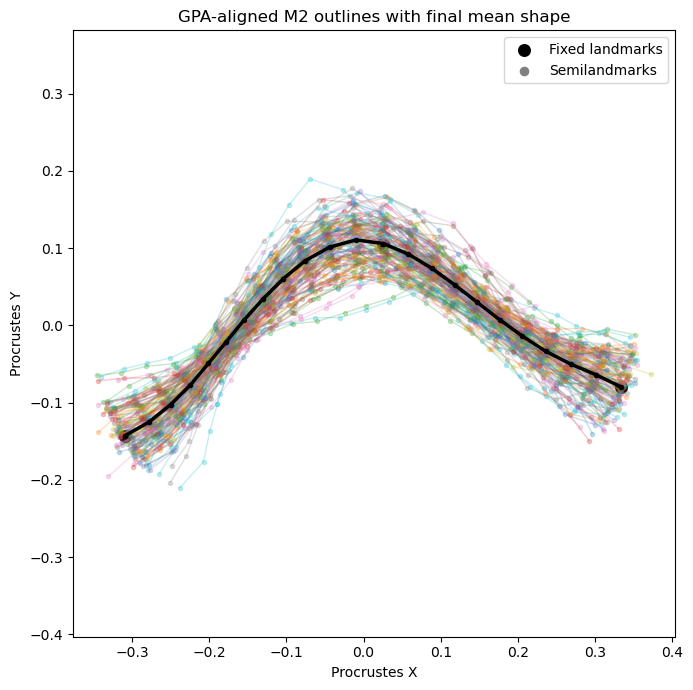

Saved: ../../results/gpa/gpa_aligned_shapes_overlay.png


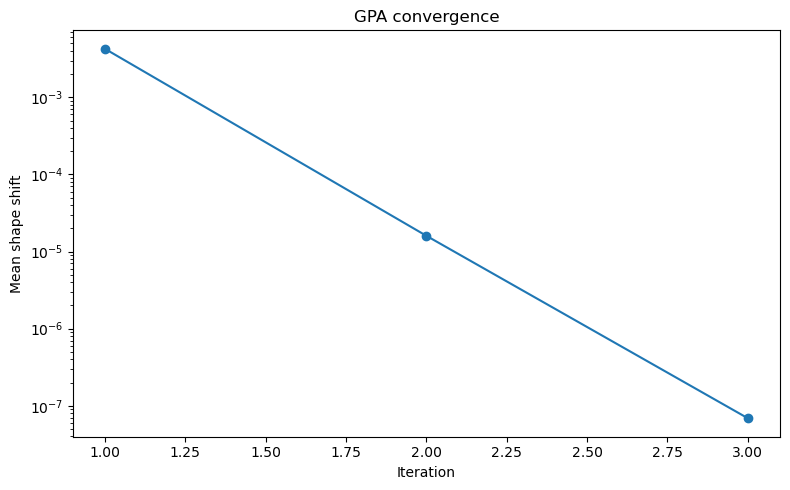

Saved: ../../results/gpa/gpa_convergence_plot.png


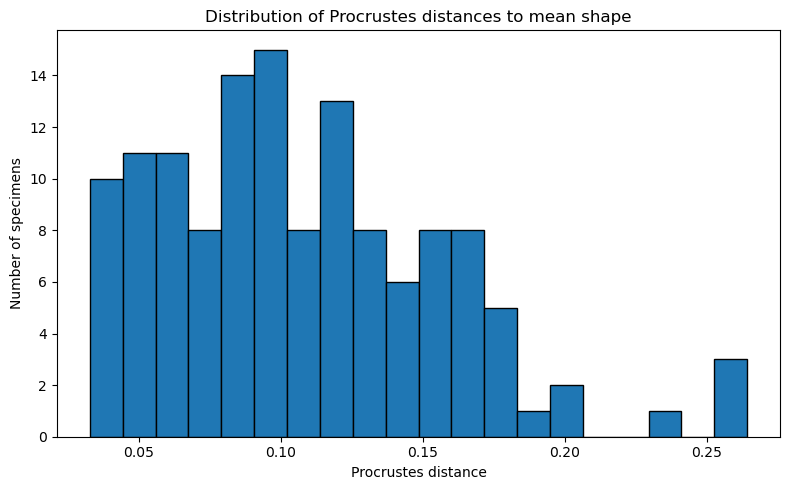

Saved: ../../results/gpa/gpa_procrustes_distance_histogram.png


In [114]:
# -----------------------------
# Plot and save GPA outputs
# -----------------------------

def plot_shape_outline(ax, shape: np.ndarray, **kwargs) -> None:
    """
    Plot a single landmark outline.
    """
    x = shape[:, 0]
    y = shape[:, 1]
    kwargs.setdefault("marker", "o")
    kwargs.setdefault("markersize", 3)
    kwargs.setdefault("linewidth", 1)
    ax.plot(x, y, **kwargs)


if SAVE_PLOTS:
    # Overlay of all aligned specimens with mean shape.
    fig, ax = plt.subplots(figsize=(7, 7))

    for shape in aligned_shapes:
        plot_shape_outline(ax, shape, alpha=0.25)

    plot_shape_outline(ax, mean_shape, color="black", linewidth=2.5)

    ax.scatter(
        mean_shape[[i for i in fixed_indices], 0],
        mean_shape[[i for i in fixed_indices], 1],
        s=70,
        color="black",
        label="Fixed landmarks"
    )

    ax.scatter(
        mean_shape[[i for i in semilandmark_indices], 0],
        mean_shape[[i for i in semilandmark_indices], 1],
        s=35,
        color="gray",
        label="Semilandmarks"
    )

    ax.set_title("GPA-aligned M2 outlines with final mean shape")
    ax.set_xlabel("Procrustes X")
    ax.set_ylabel("Procrustes Y")
    ax.axis("equal")
    ax.legend()
    plt.tight_layout()

    overlay_path = OUTPUT_DIR / "gpa_aligned_shapes_overlay.png"
    plt.savefig(overlay_path, dpi=300)
    plt.show()
    print(f"Saved: {overlay_path}")

    # Convergence plot.
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.plot(
        gpa_history["iteration"],
        gpa_history["mean_shape_shift"],
        marker="o",
    )
    ax.set_title("GPA convergence")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Mean shape shift")
    ax.set_yscale("log")
    plt.tight_layout()

    convergence_path = OUTPUT_DIR / "gpa_convergence_plot.png"
    plt.savefig(convergence_path, dpi=300)
    plt.show()
    print(f"Saved: {convergence_path}")

    # Histogram of Procrustes distances.
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.hist(procrustes_distances, bins=20, edgecolor="black")
    ax.set_title("Distribution of Procrustes distances to mean shape")
    ax.set_xlabel("Procrustes distance")
    ax.set_ylabel("Number of specimens")
    plt.tight_layout()

    distance_path = OUTPUT_DIR / "gpa_procrustes_distance_histogram.png"
    plt.savefig(distance_path, dpi=300)
    plt.show()
    print(f"Saved: {distance_path}")
else:
    print("SAVE_PLOTS is set to False, so plots were skipped.")


In [120]:
import numpy as np

# Mean of specimens actually returned by GPA
calculated_mean = aligned_shapes.mean(axis=0)

# Final reference returned by GPA
reference_mean = mean_shape

# Normalize specimen mean to match GPA reference scaling
normalized_mean = normalize_mean_shape(calculated_mean)

print(
    "Maximum raw difference:",
    np.max(np.abs(calculated_mean - reference_mean))
)

print(
    "Maximum difference after normalization:",
    np.max(np.abs(normalized_mean - reference_mean))
)

print(
    "GPA sliding enabled:",
    SLIDE_SEMILANDMARKS
)

Maximum raw difference: 0.002323027514697207
Maximum difference after normalization: 0.0
GPA sliding enabled: False


## 8. Output summary

In [ ]:
# -----------------------------
# Final output summary
# -----------------------------

print("Procrustes/GPA notebook workflow complete.")
print(f"\nOutputs saved to: {OUTPUT_DIR.resolve()}")
print("\nOutput files:")
for path in sorted(OUTPUT_DIR.glob("*")):
    print(f"- {path.name}")


In [ ]:
print("GPA saved to:", aligned_output_path.resolve())